<a href="https://colab.research.google.com/github/KaiyoDev/Nhom_3_KhaiThacDuLieu_Parkinsons/blob/m06/M06_Ph%C3%A2n_c%E1%BB%A5m_%2B_ARI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ====================  — BÀI LÀM M06: phân cụm (K-Means, DBSCAN) + ARI ====================
import datetime, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
SEED = 42

# ---------- 0. Nạp dữ liệu (ưu tiên canonical CSV của M01, dự phòng file xlsx gốc) ----------
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CSV = ROOT / "data/processed/parkinsons_v1.csv"
XLSX = ROOT / "data/raw/D07 - parkinsons.data.xlsx"
if not CSV.exists() and not XLSX.exists():
    tim = list(Path.cwd().glob("*.xlsx")) + list(Path("/content").glob("*.xlsx"))
    if tim:
        XLSX = tim[0]
    else:
        try:
            from google.colab import files
            print("Không thấy dữ liệu -> hãy chọn file D07 - parkinsons.data.xlsx")
            XLSX = Path(next(iter(files.upload())))
        except ImportError:
            raise FileNotFoundError("Cần data/processed/parkinsons_v1.csv hoặc data/raw/D07 - parkinsons.data.xlsx")

if CSV.exists():
    df = pd.read_csv(CSV, sep=None, engine="python")
    NGUON = "canonical CSV data/processed/parkinsons_v1.csv"
else:
    xl = pd.ExcelFile(XLSX)
    sheet = "parkinsons.data" if "parkinsons.data" in xl.sheet_names else xl.sheet_names[-1]
    df = xl.parse(sheet)
    NGUON = f"DỰ PHÒNG: {XLSX.name} (sheet {sheet}); M01-T2 chưa có canonical CSV"
df = df.drop(columns=[c for c in ["name"] if c in df.columns])
y = df["status"]
X = df[[c for c in df.columns if c != "status"]]               # 22 feature
print("Nguồn:", NGUON, "| kích thước:", df.shape, "| status:", y.value_counts().to_dict())

assert "status" not in X.columns and "name" not in X.columns, "LỖI: nhãn/name lẫn vào input phân cụm!"
assert X.shape[1] == 22 and X.isna().sum().sum() == 0
Xs = StandardScaler().fit_transform(X)
K_RANGE = list(range(2, 11))
labels_km, rows = {}, []
for k in K_RANGE:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(Xs)
    labels_km[k] = km.labels_
    rows.append({"K": k, "inertia": round(km.inertia_, 1),
                 "silhouette": round(silhouette_score(Xs, km.labels_), 4),
                 "kich_thuoc_cum": sorted(np.bincount(km.labels_).tolist(), reverse=True)})
km_table = pd.DataFrame(rows)
K_CHON = int(km_table.loc[km_table["silhouette"].idxmax(), "K"])
def knee_eps(Xm, min_samples):
    d, _ = NearestNeighbors(n_neighbors=min_samples).fit(Xm).kneighbors(Xm)
    kd = np.sort(d[:, -1])
    t = np.arange(len(kd)) / (len(kd) - 1)
    v = (kd - kd.min()) / (kd.max() - kd.min())
    return kd, float(kd[np.argmax(t - v)])

MS_LIST = [3, 5, 10]
kdist, knee = {}, {}
for ms in MS_LIST:
    kdist[ms], knee[ms] = knee_eps(Xs, ms)

MIN_SAMPLES = 5
EPS = round(knee[MIN_SAMPLES], 2)
labels_db = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit(Xs).labels_
n_cum_db = len(set(labels_db)) - (1 if -1 in labels_db else 0)
n_nhieu = int((labels_db == -1).sum())

EPS_GRID = [1.5, 2, 2.5, 3, 3.5, 4, 5]
grid_rows, grid_labels = [], {}
for ms in MS_LIST:
    for eps in EPS_GRID + [round(knee[ms], 2)]:
        l = DBSCAN(eps=eps, min_samples=ms).fit(Xs).labels_
        grid_labels[(ms, eps)] = l
        grid_rows.append({"min_samples": ms, "eps": eps,
                          "so_cum": len(set(l)) - (1 if -1 in l else 0), "so_nhieu": int((l == -1).sum())})
grid = pd.DataFrame(grid_rows)
km_table["ARI"] = [round(adjusted_rand_score(y, labels_km[k]), 4) for k in km_table["K"]]
ari_db = round(adjusted_rand_score(y, labels_db), 4)
grid["ARI"] = [round(adjusted_rand_score(y, grid_labels[(r.min_samples, r.eps)]), 4) for r in grid.itertuples()]
mask = labels_db != -1
sil_db = round(silhouette_score(Xs[mask], labels_db[mask]), 4) if n_cum_db >= 2 else float("nan")
lab = labels_km[K_CHON]
nho = int(np.argmin(np.bincount(lab)))
chenh = (pd.DataFrame(Xs, columns=X.columns)[lab == nho].mean()
         - pd.DataFrame(Xs, columns=X.columns)[lab != nho].mean()).sort_values(ascending=False)
meta = {"date": datetime.date.today().isoformat(), "seed": SEED, "sklearn": sklearn.__version__}
print(f"K-Means: K chọn = {K_CHON} | DBSCAN: eps={EPS}, min_samples={MIN_SAMPLES} -> {n_cum_db} cụm, {n_nhieu} nhiễu")
print("Xong Ô 1 -> chạy Ô 2 để xem và lưu kết quả")


Không thấy dữ liệu -> hãy chọn file D07 - parkinsons.data.xlsx


Saving D07_-_parkinsons_data.xlsx to D07_-_parkinsons_data.xlsx
Nguồn: DỰ PHÒNG: D07_-_parkinsons_data.xlsx (sheet parkinsons.data); M01-T2 chưa có canonical CSV | kích thước: (195, 23) | status: {1: 147, 0: 48}
K-Means: K chọn = 2 | DBSCAN: eps=3.37, min_samples=5 -> 1 cụm, 12 nhiễu
Xong Ô 1 -> chạy Ô 2 để xem và lưu kết quả


K-MEANS (silhouette, ARI so với status)
 K  silhouette     ARI K chọn
 2      0.4373 -0.0978    <--
 3      0.2763  0.0582       
 4      0.2358  0.0583       
 5      0.2048  0.1000       
 6      0.2138  0.1058       
 7      0.2094  0.0882       
 8      0.2201  0.0313       
 9      0.2265  0.0574       
10      0.1896  0.0481       

DBSCAN (eps=3.37, min_samples=5): 1 cụm, 12 nhiễu, ARI = -0.0639


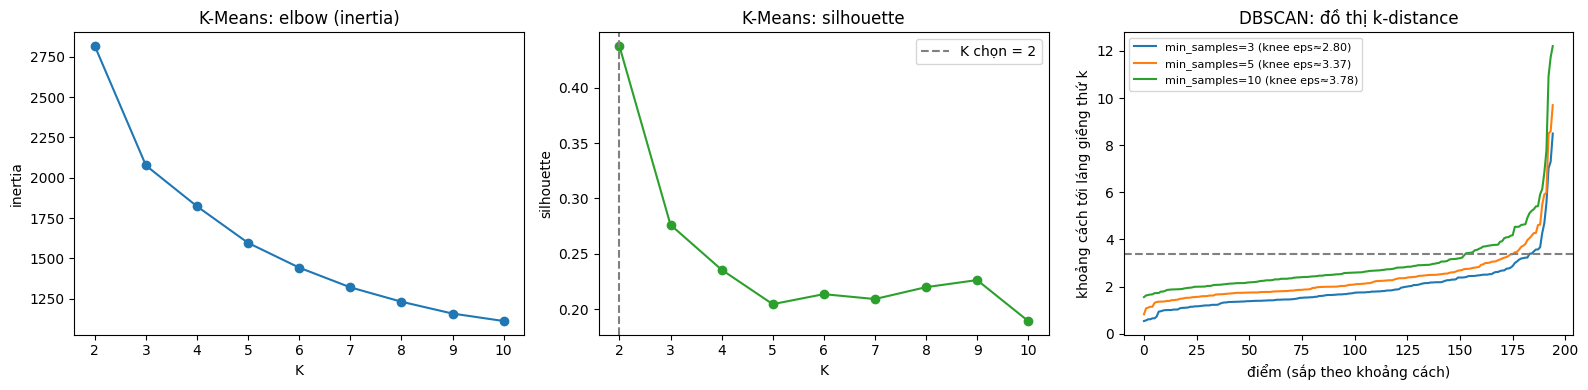

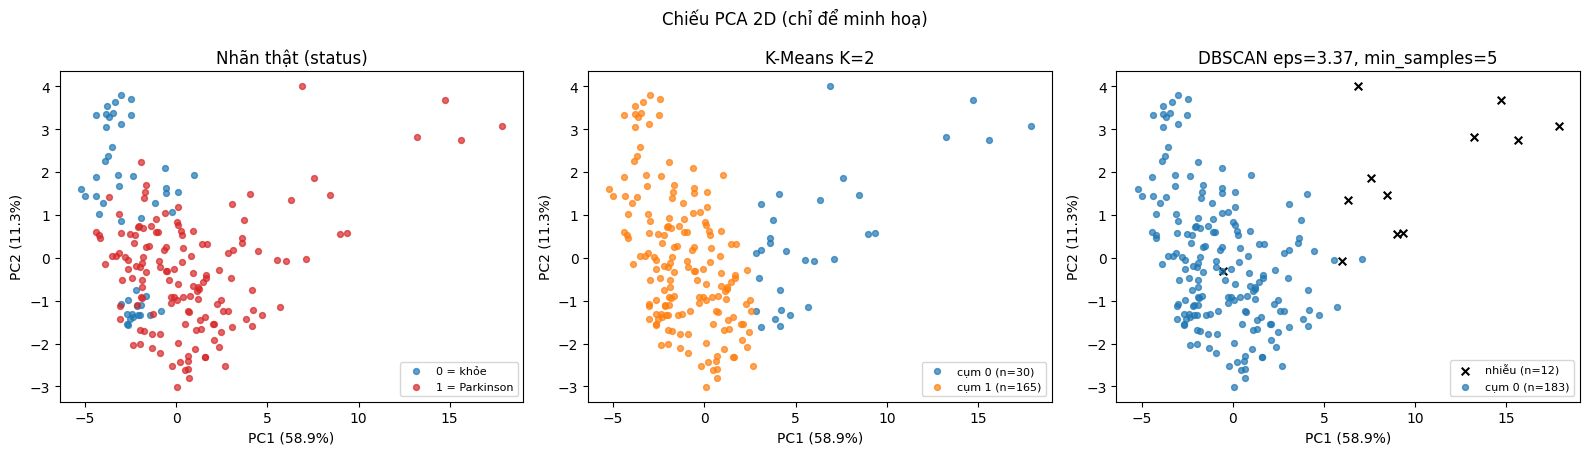


Đã lưu: results/m06_cluster_ari.csv, results/clustering_report.md, results/figures/m06_*.png


In [ ]:
# ====================  RESULTS : hiện kết quả + lưu vào results/ ====================
RES = ROOT / "results"
FIGD = RES / "figures"
FIGD.mkdir(parents=True, exist_ok=True)
hien = km_table[["K", "silhouette", "ARI"]].copy()
hien["K chọn"] = np.where(hien["K"] == K_CHON, "<--", "")
print("K-MEANS (silhouette, ARI so với status)")
print(hien.to_string(index=False))
print(f"\nDBSCAN (eps={EPS}, min_samples={MIN_SAMPLES}): {n_cum_db} cụm, {n_nhieu} nhiễu, ARI = {ari_db}")

fig_ts, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(km_table["K"], km_table["inertia"], "o-"); ax[0].set(title="K-Means: elbow (inertia)", xlabel="K", ylabel="inertia")
ax[1].plot(km_table["K"], km_table["silhouette"], "o-", color="tab:green")
ax[1].axvline(K_CHON, ls="--", color="gray", label=f"K chọn = {K_CHON}")
ax[1].set(title="K-Means: silhouette", xlabel="K", ylabel="silhouette"); ax[1].legend()
for a_ in ax[:2]:
    a_.set_xticks(K_RANGE)
for ms in MS_LIST:
    ax[2].plot(kdist[ms], label=f"min_samples={ms} (knee eps≈{knee[ms]:.2f})")
ax[2].axhline(EPS, ls="--", color="gray")
ax[2].set(title="DBSCAN: đồ thị k-distance", xlabel="điểm (sắp theo khoảng cách)", ylabel="khoảng cách tới láng giềng thứ k")
ax[2].legend(fontsize=8)
fig_ts.tight_layout()
fig_ts.savefig(FIGD / "m06_chon_tham_so.png", dpi=150, bbox_inches="tight")
plt.show()

pca = PCA(n_components=2, random_state=SEED).fit(Xs)
Z, ev = pca.transform(Xs), pca.explained_variance_ratio_
cmap = plt.get_cmap("tab10")
fig_pca, ax = plt.subplots(1, 3, figsize=(16, 4.6))
for val, mau, ten in [(0, "tab:blue", "0 = khỏe"), (1, "tab:red", "1 = Parkinson")]:
    ax[0].scatter(Z[y == val, 0], Z[y == val, 1], s=18, c=mau, alpha=0.7, label=ten)
ax[0].set_title("Nhãn thật (status)")
for c in sorted(set(lab)):
    ax[1].scatter(Z[lab == c, 0], Z[lab == c, 1], s=18, color=cmap(c), alpha=0.7, label=f"cụm {c} (n={int((lab == c).sum())})")
ax[1].set_title(f"K-Means K={K_CHON}")
for c in sorted(set(labels_db)):
    if c == -1:
        ax[2].scatter(Z[labels_db == c, 0], Z[labels_db == c, 1], s=30, c="k", marker="x", label=f"nhiễu (n={int((labels_db == c).sum())})")
    else:
        ax[2].scatter(Z[labels_db == c, 0], Z[labels_db == c, 1], s=18, color=cmap(c), alpha=0.7, label=f"cụm {c} (n={int((labels_db == c).sum())})")
ax[2].set_title(f"DBSCAN eps={EPS}, min_samples={MIN_SAMPLES}")
for a_ in ax:
    a_.set_xlabel(f"PC1 ({ev[0]:.1%})"); a_.set_ylabel(f"PC2 ({ev[1]:.1%})"); a_.legend(fontsize=8)
fig_pca.suptitle("Chiếu PCA 2D (chỉ để minh hoạ)")
fig_pca.tight_layout()
fig_pca.savefig(FIGD / "m06_pca2d_cum_vs_status.png", dpi=150, bbox_inches="tight")
plt.show()
km_rows = km_table.assign(phuong_phap="kmeans", eps=np.nan, min_samples=np.nan, so_cum=km_table["K"], so_nhieu=0)
db_row = pd.DataFrame([{"phuong_phap": "dbscan", "K": np.nan, "eps": EPS, "min_samples": MIN_SAMPLES,
                        "so_cum": n_cum_db, "so_nhieu": n_nhieu, "silhouette": sil_db, "ARI": ari_db}])
COLS = ["phuong_phap", "K", "eps", "min_samples", "so_cum", "so_nhieu", "silhouette", "ARI"]
out = pd.concat([km_rows, db_row], ignore_index=True)[COLS].assign(**meta)
out["K"], out["min_samples"] = out["K"].astype("Int64"), out["min_samples"].astype("Int64")
out.to_csv(RES / "m06_cluster_ari.csv", index=False)
sil = km_table.set_index("K")["silhouette"]
k2 = km_table[km_table.K == 2].iloc[0]
n_nho = int((lab == nho).sum())
n_nho_pd = int(((lab == nho) & (y.values == 1)).sum())
noise_pd = int(((labels_db == -1) & (y.values == 1)).sum())
ghi_chu = " Dữ liệu lấy từ xlsx gốc vì chưa có canonical CSV (M01-T2); cần chạy lại khi có." if NGUON.startswith("DỰ PHÒNG") else ""
bang = "\n".join(["| K | Silhouette | ARI |", "|---|---|---|"] +
                 [f"| {int(r.K)}{' (chọn)' if int(r.K) == K_CHON else ''} | {r.silhouette:.4f} | {r.ARI:.4f} |"
                  for r in km_table.itertuples()])

REPORT = f"""# M06-T1/T2 · Kết quả phân cụm + ARI (Nhóm 3 · Parkinson)

- Người làm: M06 · Ngày chạy: {meta['date']} · Notebook: `notebooks/04_clustering.ipynb` · Kết quả thô: `results/m06_cluster_ari.csv`
- Reviewer: M05 (T1), M01 gate (T2) · Trạng thái: chờ review

**Thiết lập:** 22 feature chuẩn hoá `StandardScaler` (không có `status`/`name`); seed {SEED}. K-Means K=2..10, chọn K theo silhouette cao nhất. DBSCAN `min_samples={MIN_SAMPLES}`, `eps={EPS}` (knee đồ thị k-distance). ARI so với `status` (nhiễu -1 tính là một nhóm).

## Kết quả

{bang}

**DBSCAN:** {n_cum_db} cụm, {n_nhieu} điểm nhiễu, ARI = {ari_db:.4f}.

Hình: `results/figures/m06_chon_tham_so.png`, `results/figures/m06_pca2d_cum_vs_status.png`.

## Quan sát

- ARI ≈ 0 ở cả K-Means ({km_table['ARI'].min():.4f} đến {km_table['ARI'].max():.4f}) và DBSCAN ({ari_db:.4f}).
- K=2 tách cụm nhỏ {n_nho} mẫu, {n_nho_pd}/{n_nho} có status=1; DBSCAN có {noise_pd}/{n_nhieu} điểm nhiễu có status=1.
- Lưu ý: dữ liệu nhỏ ({len(y)} mẫu), lệch lớp ({int((y == 1).sum())}/{int((y == 0).sum())}); chuẩn hoá lại vì chưa có feature matrix M04-T1.{ghi_chu}

## Kết luận

*(Để trống: M06 và reviewer cùng kết luận.)*
"""
(RES / "clustering_report.md").write_text(REPORT, encoding="utf-8")
print("\nĐã lưu: results/m06_cluster_ari.csv, results/clustering_report.md, results/figures/m06_*.png")
